# Barra ejemplo: cómo se mide una barra, paso a paso

Galaxia DESI `TARGETID 39627835815496281` (z = 0.039): barra fuerte con un anillo interno.
Cada paso llama a una función de `src/` y muestra su resultado; el método completo es `measure_image` en `src/measure.py`.
Referencia (Alonso et al. 2024, catálogo de Valeria): semilargo **14.05″**.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import bar, fourier, isophotes
from src.cutout import pixscale
from src.measure import A_MIN, measure_fits
from tools import steps

NAME, Z, A_REF = "39627835815496281", 0.03941, 14.05
PS = pixscale("desi")  # arcsec/px
FITS_PATH = ROOT / f"outputs/cutouts/{NAME}_desi_r.fits"

## 0. La imagen
Se mide sobre el FITS de **una banda** (r): un número de flujo por píxel, sin color. El JPG combina tres bandas y sirve solo para mirar.

(866, 866) px = 227 arcsec


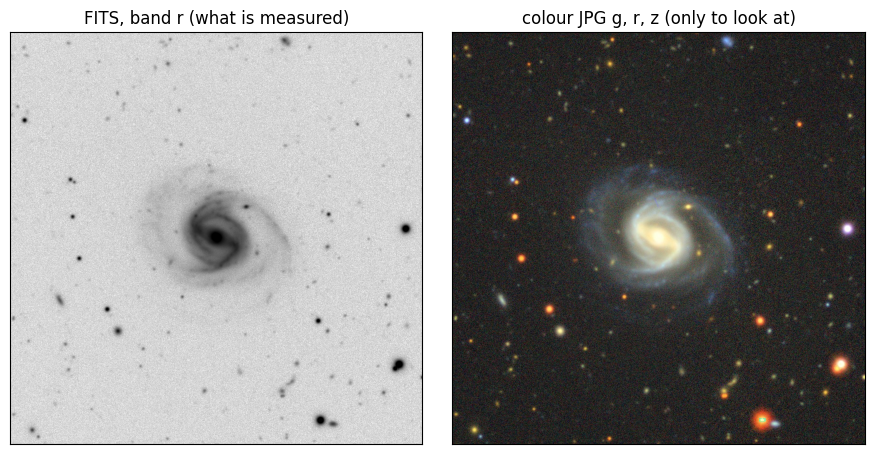

In [2]:
img = fits.getdata(FITS_PATH).astype(float)
steps.show_image(img, plt.imread(ROOT / f"outputs/cutouts/{NAME}_desi.jpg"))
assert img.ndim == 2 and np.isfinite(img).all()
print(img.shape, "px =", round(img.shape[0] * PS), "arcsec")

## 1. Cielo y máscara
Se estima el nivel del cielo y se detectan las fuentes; todo lo que no es la región central (la galaxia) se enmascara.

cielo 0.0011 ± 0.0040 nanomaggies,  enmascarado 4.6 % de la imagen


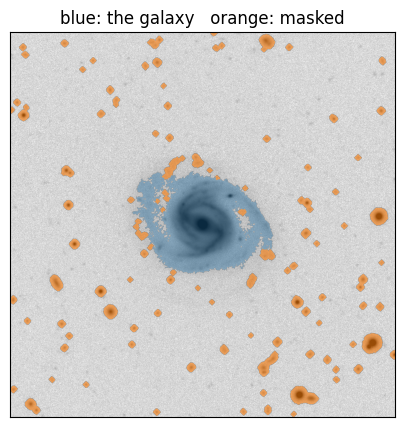

In [3]:
sky, sky_std, mask, galaxy = isophotes.sky_and_mask(img)
img = img - sky
steps.show_mask(img, mask, galaxy)
assert not (mask & galaxy).any()
print(f"cielo {sky:.4f} ± {sky_std:.4f} nanomaggies,  enmascarado {100 * mask.mean():.1f} % de la imagen")

## 2. Centro
El píxel más brillante de la galaxia cerca del centro del recorte (no de toda la galaxia: una estrella pegada ganaría).

In [4]:
x0, y0 = isophotes.galaxy_centre(img, galaxy)
c = (np.array(img.shape) - 1) / 2
assert np.hypot(x0 - c[1], y0 - c[0]) < 10
print(f"centro ({x0:.1f}, {y0:.1f}) px, a {np.hypot(x0 - c[1], y0 - c[0]) * PS:.2f}″ del centro del recorte")

centro (432.8, 433.0) px, a 0.16″ del centro del recorte


## 3. Isofotas
En cada radio se ajusta la elipse de brillo constante; de ellas salen la elipticidad ε(a) y el ángulo PA(a).

105 isofotas, 99 % convergidas, hasta 43″


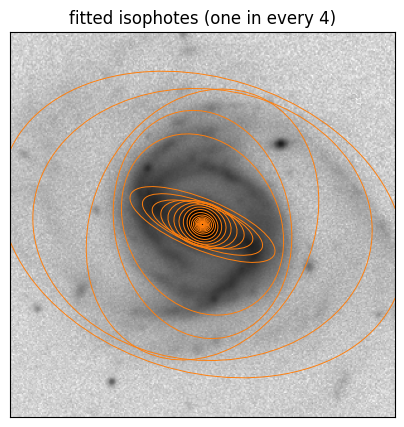

In [5]:
yy, xx = np.nonzero(galaxy)
r_gal = np.hypot(xx - x0, yy - y0).max()
t = isophotes.fit_isophotes(img, mask, x0, y0, maxsma=r_gal)
steps.show_isophotes(img, t, x0, y0, half=40 / PS)
good = np.isin(t["stop_code"], isophotes.GOOD_STOP).mean()
assert good > 0.8
print(f"{len(t)} isofotas, {100 * good:.0f} % convergidas, hasta {t['sma'].max() * PS:.0f}″")

## 4. Largo y ángulo de la barra
La barra es el **primer** pico de ε ≥ 0.25 seguido de una caída de 0.1 (Marinova & Jogee 2007); su radio es el semilargo y su PA, la orientación.

semilargo 15.41″ (ref 14.05″),  ε = 0.67,  flags: True, True, True


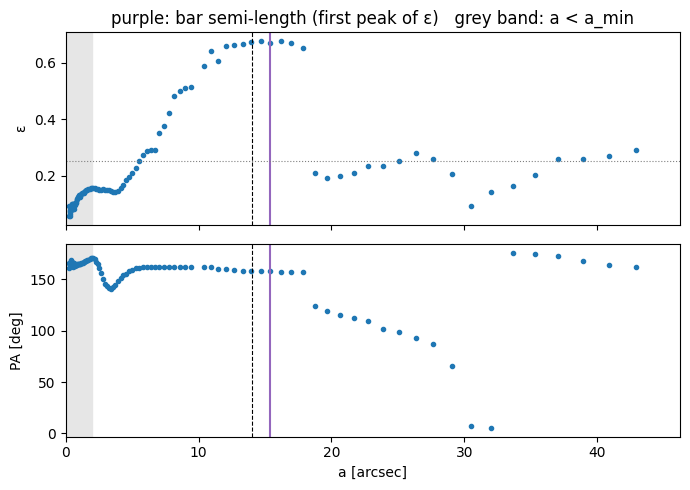

In [6]:
a, eps, pa = bar.profiles(t, PS)
b = bar.bar_from_profile(a, eps, pa, A_MIN)
steps.show_profiles(a, eps, pa, b, A_MIN, a_ref=A_REF)
assert b["flag_eps"] and b["flag_end"]
print(f"semilargo {b['a_eps']:.2f}″ (ref {A_REF}″),  ε = {b['eps_bar']:.2f},  flags: {b['flag_eps']}, {b['flag_end']}, {b['flag_pa']}")

## 5. Modos de Fourier
En cada círculo el brillo se separa en ondas: m = 0 es lo redondo (bulbo + disco), m = 2 sube dos veces por vuelta: la barra.

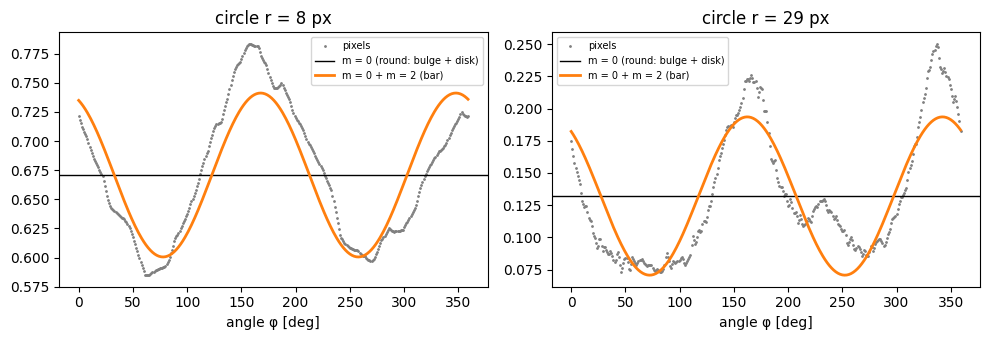

In [7]:
r, a0, am, bm = fourier.polar_modes(img, mask, x0, y0, rmax=r_gal)
steps.show_modes(img, r, a0, am, bm, x0, y0, radii_px=[2 / PS, 0.5 * b["a_eps"] / PS])
assert np.isfinite(a0[: int(b["a_eps"] / PS)]).all()

## 6. Ancho sin bulbo
La imagen hecha solo con m = 2, 4, 6 no tiene bulbo ni disco; el ancho es su anchura a media altura (FWHM) a 0.5 y 0.75 del largo.

ancho 7.21″  (la isofota, con bulbo, daría 10.18″)


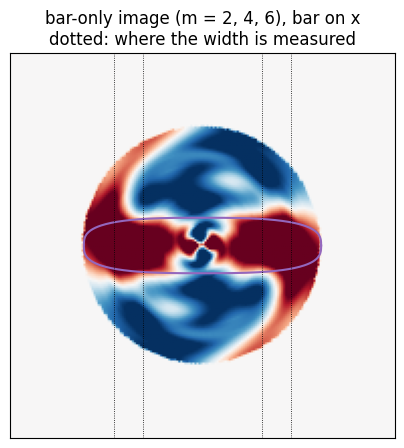

In [8]:
w = fourier.bar_width(x0, y0, r, am, bm, b["a_eps"] / PS, b["pa_bar"]) * PS
bo = fourier.bar_only_image(img.shape, x0, y0, r, am, bm, b["a_eps"] / PS)
steps.show_bar_only(bo, x0, y0, 25 / PS, b["pa_bar"], b["a_eps"] / PS, w / PS)
assert 0 < w < 2 * b["a_eps"]
print(f"ancho {w:.2f}″  (la isofota, con bulbo, daría {2 * b['a_eps'] * (1 - b['eps_bar']):.2f}″)")

## 7. Tamaño físico
Con z y Planck18; proyectado en el cielo, como en el paper.

In [9]:
scale = bar.kpc_per_arcsec(Z)
print(f"{scale:.3f} kpc/″:  L = {2 * b['a_eps'] * scale:.1f} kpc,  W = {w * scale:.1f} kpc")

0.807 kpc/″:  L = 24.9 kpc,  W = 5.8 kpc


## Todo en una línea
`measure_fits` hace los pasos 1–7 sobre cualquier FITS (la escala de píxel la lee del encabezado).

{'a_bar': 15.406,
 'W_bar': 7.205,
 'pa_bar': 67.668,
 'L_kpc': 24.864,
 'W_kpc': 5.814}

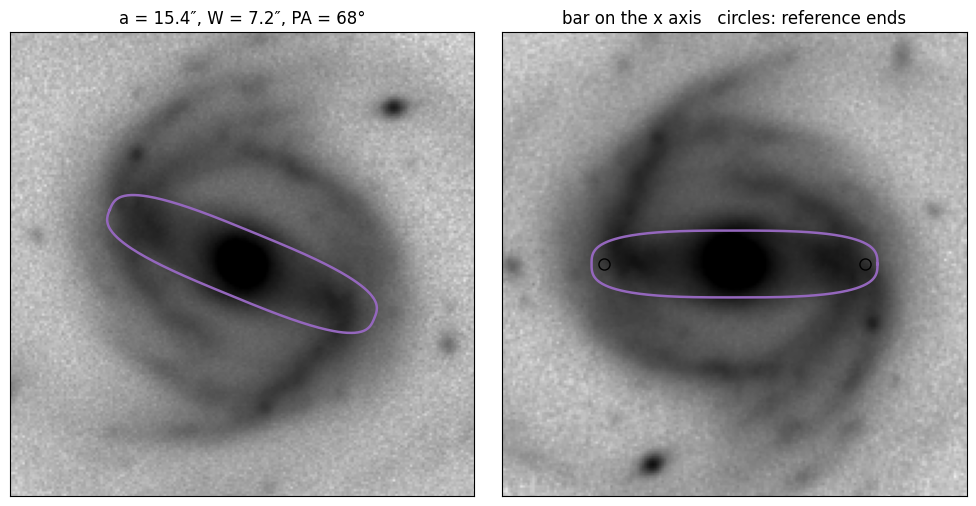

In [10]:
res = measure_fits(FITS_PATH, z=Z)
steps.show_bar(img, res, PS, half=25 / PS, a_ref=A_REF)
assert np.isclose(res["a_bar"], b["a_eps"]) and np.isclose(res["W_bar"], w)
{k: round(float(v), 3) for k, v in res.items() if k in ("a_bar", "W_bar", "pa_bar", "L_kpc", "W_kpc")}